In [2]:
!pip install requests pandas matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



Weather Data:
                  Date  Temperature  Humidity
0  2026-11-02 15:00:00        24.26        66
1  2026-11-02 18:00:00        23.74        68
2  2026-11-02 21:00:00        23.15        68
3  2026-11-03 00:00:00        22.27        71
4  2026-11-03 03:00:00        24.43        61

Average Temperature: 25.30575
Maximum Temperature: 30.76
Minimum Temperature: 19.92
Average Humidity: 54.375


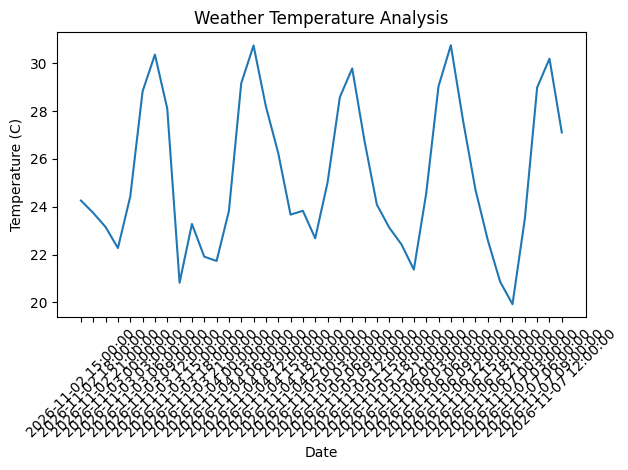

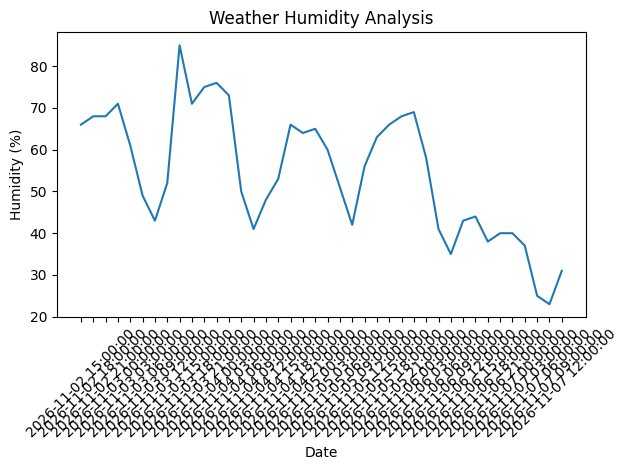


Weather data saved successfully!


In [8]:

import requests
import pandas as pd
import matplotlib.pyplot as plt

api_key = "fb365aa6104829b44455572365ff3b4e"
city = "Nashik"

url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    "q": city,
    "appid": api_key,
    "units": "metric"
}

# Fetch data
response = requests.get(url, params=params)
data = response.json()

# Check API response
if "list" not in data:
    print("API Error:", data.get("message", data))
else:
    weather = []

    # Extract weather data
    for item in data["list"]:
        weather.append({
            "Date": item["dt_txt"],
            "Temperature": item["main"]["temp"],
            "Humidity": item["main"]["humidity"]
        })

    # Create DataFrame
    df = pd.DataFrame(weather)

    print("\nWeather Data:")
    print(df.head())

    # Analyze data
    print("\nAverage Temperature:", df["Temperature"].mean())
    print("Maximum Temperature:", df["Temperature"].max())
    print("Minimum Temperature:", df["Temperature"].min())
    print("Average Humidity:", df["Humidity"].mean())

    # Plot temperature
    plt.plot(df["Date"], df["Temperature"])
    plt.xlabel("Date")
    plt.ylabel("Temperature (C)")
    plt.title("Weather Temperature Analysis")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot humidity
    plt.plot(df["Date"], df["Humidity"])
    plt.xlabel("Date")
    plt.ylabel("Humidity (%)")
    plt.title("Weather Humidity Analysis")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Save data
    df.to_csv("weather_data.csv", index=False)
    print("\nWeather data saved successfully!")


In [7]:
import requests

api_key = "fb365aa6104829b44455572365ff3b4e"

url = "https://api.openweathermap.org/data/2.5/weather"

params = {
    "q": "Nashik",
    "appid": api_key,
    "units": "metric"
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'coord': {'lon': 73.8, 'lat': 19.9833}, 'weather': [{'id': 804, 'main': 'Clouds', 'description': 'overcast clouds', 'icon': '04n'}], 'base': 'stations', 'main': {'temp': 24.29, 'feels_like': 24.52, 'temp_min': 24.29, 'temp_max': 24.29, 'pressure': 1015, 'humidity': 67, 'sea_level': 1015, 'grnd_level': 942}, 'visibility': 10000, 'wind': {'speed': 1.01, 'deg': 34, 'gust': 1.1}, 'clouds': {'all': 100}, 'dt': 1793628095, 'sys': {'country': 'IN', 'sunrise': 1793581588, 'sunset': 1793622609}, 'timezone': 19800, 'id': 1261731, 'name': 'Nashik', 'cod': 200}
